# Boltzmann transport in silicon

In this tutorial you compute the electronic transport of bulk silicon from a PAO Hamiltonian built as in the [bands and DOS tutorial](tutorial01.ipynb). First you evaluate the conductivity, the Seebeck coefficient and the electronic thermal conductivity as functions of the chemical potential $\mu$, in the constant relaxation-time approximation. Then you fix the electron density of n-type Si at $10^{19}$ cm$^{-3}$ and find $\mu(T)$ between 300 and 800 K. Last, you compute the resistivity with relaxation times from scattering models, one of which you write yourself. The methods are {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.transport`, {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.doping` and the {py:class}`~PAOFLOW.boltzmann.TauModel.TauModel` class.

**What you will compute**

- The Boltzmann transport tensors from the band velocities, in the constant relaxation-time approximation
- The chemical potential at fixed carrier density, and what limits its accuracy on an interpolated k-mesh
- Relaxation times from acoustic-phonon and ionised-impurity scattering, combined by Matthiessen's rule
- A relaxation-time model of your own, and the resistivity $\rho(T)$ of n-type Si

:::{tip}
This page is built on the case [`si_bands_transport`](https://github.com/marcobn/PAOFLOW/tree/develop/examples/cases/si_bands_transport): open it in PAOFLOW Studio with *Examples…* → `si_bands_transport`, or copy it with `paoflow-gen --example si_bands_transport`. The notebook is the workflow of this page: it starts from the DFT output of the case and reads the projections of `projwfc.x`, which the input {download}`proj.in <tutorial02/proj.in>` of this page adds to the QE runs of the case. To change the doping or the scattering models, or start a transport calculation of your own material from this workflow, {download}`download this notebook <tutorial02.ipynb>`. The notebook reads the DFT output of the case, the file `si_bands_transport-v1.tar.gz` of the release [case-data](https://github.com/marcobn/PAOFLOW/releases/tag/case-data), which the first code cell downloads and extracts next to the notebook unless `silicon.save` is already there. On a machine without internet access, download the file by hand and extract it in the directory you run in with `tar xzf si_bands_transport-v1.tar.gz`. The notebook runs in about two minutes on one core and needs 2.9 GB of memory. This tutorial assumes the [bands and DOS tutorial](tutorial01.ipynb).
:::

## Required input

This tutorial reads the QE calculation of bulk Si made by the inputs of the case and of this page: the self-consistent run (`scf.in`) and the non-self-consistent run on the full k grid (`nscf.in`) of the bands and DOS tutorial, followed by the projections of the Kohn–Sham states onto the atomic orbitals of the pseudopotential (`proj.in`). PAOFLOW reads three files of `silicon.save`:

- `data-file-schema.xml`: the crystal structure, the k-points and the Kohn–Sham eigenvalues;
- `atomic_proj.xml`: the projections and the overlaps of the atomic orbitals, written by `projwfc.x`;
- `Si.pbe-tm-new-gipaw-v2.1.UPF`: the pseudopotential, copied there by `pw.x`, whose atomic orbitals define the PAO basis.

Transport needs nothing more from the DFT run, because the dense k-mesh comes from the Fourier interpolation of the PAO Hamiltonian.

If you would like to create the `.save` directory yourself instead of downloading it, run in the case folder

```bash
mpirun -np 4 pw.x -in scf.in > scf.out
mpirun -np 4 pw.x -in nscf.in > nscf.out
mpirun -np 4 projwfc.x -in proj.in > proj.out
```

To run this notebook on your own calculation, set `savedir` in the next cell to its `.save` directory; the download then does not run.

In [1]:
from pathlib import Path
from tarfile import open as open_tar
from urllib.request import urlretrieve

savedir = 'silicon.save'
outputdir = 'output'

# fetch the DFT output of the case from the release named in the tip, unless it is here already
if not Path(savedir).is_dir():
    archive = Path('si_bands_transport-v1.tar.gz')
    if not archive.is_file():
        urlretrieve(
            'https://github.com/marcobn/PAOFLOW/releases/download/'
            'case-data/si_bands_transport-v1.tar.gz',
            archive,
        )
    with open_tar(archive, 'r:gz') as tar:
        members = [m for m in tar.getmembers() if m.name.startswith('silicon.save/')]
        tar.extractall(members=members, filter='data')

## PAO Hamiltonian and band velocities on a $36\times36\times36$ mesh

In this step you build the PAO Hamiltonian and the band velocities as in the [bands and DOS tutorial](tutorial01.ipynb), with other projections and two other settings.

The projections are those of `projwfc.x` ({download}`proj.in <tutorial02/proj.in>` of this page), onto the $3s$, $3p$ and $3d$ pseudo-orbitals of the pseudopotential. `read_atomic_proj_QE()` reads them from `atomic_proj.xml`. The bands and DOS tutorial uses the internal projections instead (see its tip on `projwfc.x` in [Projecting the Kohn–Sham states onto the PAO basis](tutorial01.ipynb#projecting-the-kohnsham-states-onto-the-pao-basis)).

The two settings serve the doped semiconductor of the later steps. Its electrons occupy only the states within a few $k_BT$ of the six conduction-band minima, and both settings make sure these few states are described accurately.

First, interpolate onto a $36^3$ mesh instead of the default $24^3$. At this doping, $\mu$ is set by the few states just above the conduction-band minimum (CBM), and the default mesh samples them too coarsely: only 12 of its states lie within 50 meV above the CBM, against 60 on the $36^3$ mesh. As a result, $\mu$ at 300 K for $10^{19}$ electrons per cm$^3$ depends on the mesh:

| Mesh | $\mu$ at 300 K (eV) |
| --- | --- |
| $24^3$ | 0.649 |
| $36^3$ | 0.700 |
| $48^3$ | 0.714 |

The $36^3$ mesh is the compromise between accuracy and memory. It is within 14 meV of the $48^3$ value and needs 2.9 GB, where $48^3$ needs about 6 GB.

Second, keep a floor on the adaptive Gaussian widths, as in the bands and DOS tutorial, here `min_width=0.01` eV. The adaptive width of a state at a band extremum vanishes. Without the floor, these states become spikes on the energy grid on which the electrons of the doped semiconductor are counted, and that count must be accurate to better than $10^{-4}$ electrons per cell ([Band extrema, flat bands and the width floor](../theory/density-of-states.md#band-extrema-flat-bands-and-the-width-floor)).

In [2]:
from PAOFLOW import PAOFLOW

paoflow = PAOFLOW.PAOFLOW(savedir=savedir, outputdir=outputdir, smearing='gauss')
paoflow.read_atomic_proj_QE()
paoflow.projectability()
paoflow.pao_hamiltonian()
paoflow.interpolated_hamiltonian(nfft1=36, nfft2=36, nfft3=36)
paoflow.pao_eigh()
paoflow.gradient_and_momenta()
paoflow.adaptive_smearing(min_width=0.01)


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Estimated maximum array size: 0.11 GBytes

Initialization in:                          0.006 sec


Projectability in:                          0.923 sec


Building Hks in:                            0.330 sec


k -> R in:                                  0.013 sec


New estimated maximum array size: 2.90 GBytes
R -> k with Zero Padding in:                0.448 sec


Eigenvalues in:                             2.821 sec


Gradient in:                                2.804 sec


Momenta in:                                 2.638 sec


Adaptive Smearing in:                       0.565 sec


## Transport tensors in the constant relaxation-time approximation

In this step you compute the conductivity and the Seebeck coefficient of Si at 300 K as functions of the chemical potential $\mu$. `transport()` solves the Boltzmann equation in the relaxation-time approximation. In this approximation, scattering returns the occupation of each state $n\mathbf{k}$ to equilibrium at a rate $1/\tau_{n\mathbf{k}}$ ([Linearised Boltzmann equation](../theory/boltzmann-transport.md#linearised-boltzmann-equation)). Every coefficient that `transport()` writes is built from the moments

$$
\mathcal{L}^{(\alpha)}_{ij}(\mu, T) = \frac{2}{\Omega N_\mathrm{mesh}} \sum_{n\mathbf{k}} \tau_{n\mathbf{k}}\, v^i_{n\mathbf{k}}\, v^j_{n\mathbf{k}} \left(-\frac{\partial f}{\partial\varepsilon}\right)_{\varepsilon_{n\mathbf{k}}} (\varepsilon_{n\mathbf{k}} - \mu)^\alpha , \qquad \alpha = 0, 1, 2 ,
$$

where $f$ is the Fermi–Dirac distribution at $\mu$ and $T$, $\Omega$ the cell volume and the factor 2 the spin degeneracy. Only states within a few $k_BT$ of $\mu$ contribute, each weighted by $\tau v^2$. With `smearing='gauss'`, each state enters as its adaptive Gaussian folded with $-\partial f/\partial\varepsilon$. The spacing of the $\mu$ grid must therefore be finer than the 10 meV floor of the widths ([Transport distribution and smearing](../theory/boltzmann-transport.md#transport-distribution-and-smearing)).

The transport coefficients are combinations of these moments. The conductivity is $\sigma = e^2\mathcal{L}^{(0)}$. The Seebeck coefficient, $S = -[\mathcal{L}^{(0)}]^{-1}\mathcal{L}^{(1)}/(eT)$, is the mean energy that a carrier transports above $\mu$, divided by $eT$. Its sign tells which carriers dominate: $S$ is positive where holes carry the current and negative where electrons do.

The thermal-conductivity file holds $\kappa_0 = \mathcal{L}^{(2)}/T$, the heat conductance at zero electric field. The electronic thermal conductivity $\kappa$ is measured at zero current instead. For cubic Si it is smaller than $\kappa_0$ by $T S^2\sigma$, a difference that is large where $|S|$ is large, in and near the gap. [Conductivity, Seebeck coefficient and thermal conductivity](../theory/boltzmann-transport.md#conductivity-seebeck-coefficient-and-thermal-conductivity) gives the formulas and how to obtain $\kappa$ from the files.

These expressions leave the relaxation time $\tau_{n\mathbf{k}}$ open. Without scattering channels, `transport()` sets it to 1 s for every state, which is the constant relaxation-time approximation. The files then contain $\sigma/\tau$, $\kappa_0/\tau$ and the power factor $S^2\sigma/\tau$. The Seebeck coefficient is a ratio of moments, so it does not depend on $\tau$ ([Constant relaxation time](../theory/boltzmann-transport.md#constant-relaxation-time)).

The dependence on $\mu$ rests on a second approximation, that of rigid bands. Changing $\mu$ moves the electrons through the bands of the undoped crystal, as if Si were doped without changing its electronic structure ([Rigid-band approximation](../theory/boltzmann-transport.md#rigid-band-approximation)).

The call evaluates the tensors on 551 values of $\mu$ from $-1$ to 1.75 eV, a 5 meV spacing. This range spans the top of the valence band, the 0.754 eV gap and the bottom of the conduction band.

**Output:** four files, each with the columns $T$ (K), $\mu$ (eV), then the components $xx$, $yy$, $zz$, $xy$, $xz$, $yz$. [Units, spin factor and normalisation](../theory/boltzmann-transport.md#units-spin-factor-and-normalisation) explains the units.

| File | Quantity | Unit |
| --- | --- | --- |
| `sigmagauss_0.dat` | $\sigma/\tau$ | S m$^{-1}$ s$^{-1}$ |
| `Seebeckgauss_0.dat` | $S$ | V/K |
| `kappagauss_0.dat` | $\kappa_0/\tau$ | W m$^{-1}$ K$^{-1}$ s$^{-1}$ |
| `PFgauss_0.dat` | $S^2\sigma/\tau$ | W m$^{-1}$ K$^{-2}$ s$^{-1}$ |

In [3]:
paoflow.transport(tmin=300.0, tmax=300.0, emin=-1.0, emax=1.75, ne=551)

Transport in:                               6.445 sec


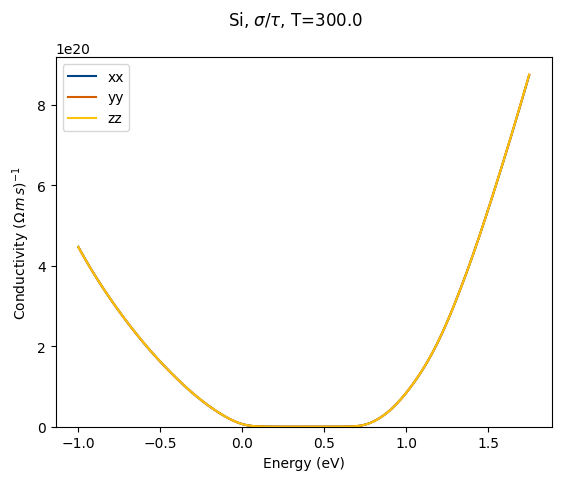

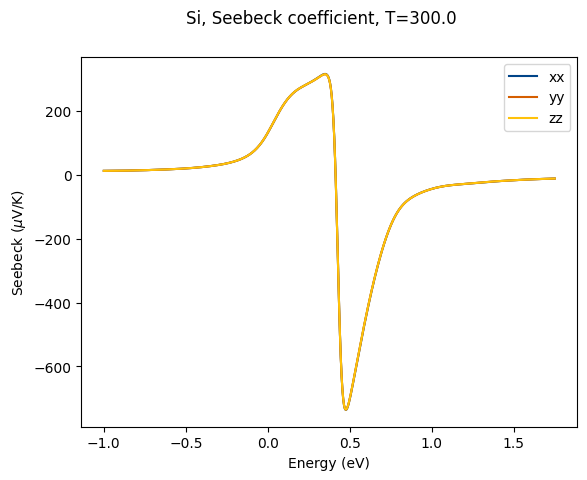

In [4]:
from pathlib import Path

from PAOFLOW import GPAO

output = Path('output')
palette = ['#004488', '#D55E00', '#FFC20A']
plotter = GPAO.GPAO()
plotter.plot_electrical_conductivity(
    str(output / 'sigmagauss_0.dat'), title='Si, $\\sigma/\\tau$', col=palette
)
plotter.plot_seebeck(
    str(output / 'Seebeckgauss_0.dat'), title='Si, Seebeck coefficient', col=palette
)

The energy zero is the valence-band maximum (VBM), and the CBM is at 0.754 eV.

Inside the gap, $\sigma/\tau$ falls by five orders of magnitude, to $1.9\times10^{14}$ S m$^{-1}$ s$^{-1}$ at $\mu = 0.425$ eV. It rises again as $\mu$ enters a band. At 0.1 eV inside the valence and the conduction band it is $2.45\times10^{19}$ and $2.49\times10^{19}$ S m$^{-1}$ s$^{-1}$.

The Seebeck coefficient changes sign at $\mu = 0.41$ eV, where the hole and electron contributions cancel. Its magnitude is largest inside the gap. As $\mu$ moves into a band, the carriers become degenerate and $|S|$ drops:

| $\mu$ | $S$ ($\mu$V/K) |
| --- | --- |
| 0.35 eV, in the gap | $+316$, the maximum |
| 0.475 eV, in the gap | $-736$, the minimum |
| at the CBM | $-152$ |
| 0.1 eV above the CBM | $-81$ |

The extremes depend on the gap, so with the PBE gap they are not those of real Si.

For cubic Si the conductivity tensor is isotropic: the three diagonal components are equal, and the off-diagonal ones vanish. On a finite mesh they agree only to within the sampling error. Check this wherever the conductivity is not negligible, that is, where $\sigma_{xx}/\tau$ exceeds $10^{-3}$ of its largest value:

In [5]:
import numpy as np

sigma = np.loadtxt('output/sigmagauss_0.dat')
relevant = sigma[:, 2] > 1e-3 * sigma[:, 2].max()
diag = sigma[relevant, 2:5]
offdiag = sigma[relevant, 5:8]
print(
    f'max |s_yy - s_xx|, |s_zz - s_xx| / s_xx: {np.max(np.abs(diag[:, 1:] - diag[:, [0]]) / diag[:, [0]]):.2e}'
)
print(f'max |s_xy|, |s_xz|, |s_yz| / s_xx:       {np.max(np.abs(offdiag) / diag[:, [0]]):.2e}')

max |s_yy - s_xx|, |s_zz - s_xx| / s_xx: 1.03e-02
max |s_xy|, |s_xz|, |s_yz| / s_xx:       9.74e-02


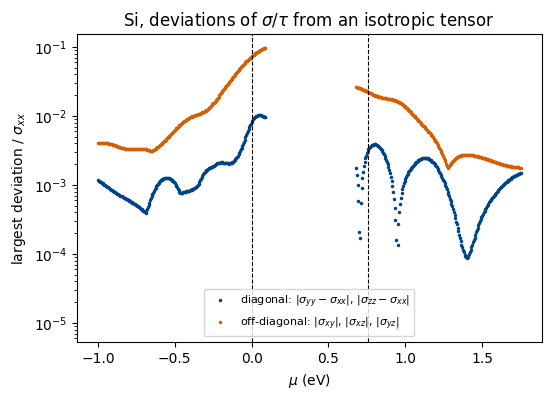

In [6]:
import matplotlib.pyplot as plt
import numpy as np

sigma = np.loadtxt('output/sigmagauss_0.dat')
mu, xx = sigma[:, 1], sigma[:, 2]
relevant = xx > 1e-3 * xx.max()
diag_dev = np.max(np.abs(sigma[:, 3:5] - xx[:, None]), axis=1) / xx
offdiag = np.max(np.abs(sigma[:, 5:8]), axis=1) / xx

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(
    mu[relevant],
    diag_dev[relevant],
    '.',
    ms=3,
    color='#004488',
    label=r'diagonal: $|\sigma_{yy}-\sigma_{xx}|$, $|\sigma_{zz}-\sigma_{xx}|$',
)
ax.semilogy(
    mu[relevant],
    offdiag[relevant],
    '.',
    ms=3,
    color='#D55E00',
    label=r'off-diagonal: $|\sigma_{xy}|$, $|\sigma_{xz}|$, $|\sigma_{yz}|$',
)
for edge in (0.0, 0.754):
    ax.axvline(edge, color='#000000', lw=0.8, ls='--')
ax.set_xlabel(r'$\mu$ (eV)')
ax.set_ylabel(r'largest deviation / $\sigma_{xx}$')
ax.set_title(r'Si, deviations of $\sigma/\tau$ from an isotropic tensor')
ax.legend(fontsize=8, loc='lower center')
plt.show()

On this mesh the diagonal components agree to within 1.0%, and the off-diagonal components reach 9.7% of $\sigma_{xx}$. Both deviations are largest near the VBM, the left dashed line, where three bands are degenerate at $\Gamma$. Near the CBM, the right dashed line, the off-diagonal components are about 2.5% of $\sigma_{xx}$. Deep inside the bands they are below 0.5%.

These deviations are the numerical error of the interpolated tensors on this mesh. For cubic Si, treat off-diagonal components of this size as zero, and use the average of the diagonal components, as the resistivity below does.

## Chemical potential of n-type Si at fixed carrier density

In this step you find the chemical potential $\mu(T)$ of Si with $10^{19}$ extra electrons per cm$^3$ between 300 and 800 K, in contrast to the previous step, where $\mu$ was a free parameter. A doped sample holds a fixed number of carriers, so its $\mu$ moves with temperature. `doping()` finds, for each temperature, the $\mu$ at which the bands hold the electrons of the undoped crystal plus the extra ones:

$$
2\int_{\varepsilon_\mathrm{min}}^{\varepsilon_\mathrm{max}} g(\varepsilon)\, f(\varepsilon; \mu, T)\, d\varepsilon = N_\mathrm{el} - n_d\,\Omega ,
$$

with these symbols:

| Symbol | Meaning | Argument of `doping()` |
| --- | --- | --- |
| $g(\varepsilon)$ | DOS per spin, defined as in the bands and DOS tutorial, on the $36\times36\times36$ mesh | |
| $N_\mathrm{el}$ | valence electrons per cell, $N_\mathrm{el} = 8$ | |
| $n_d$ | doping in cm$^{-3}$, negative for n-type | `doping_conc` |
| $\varepsilon_\mathrm{min}$, $\varepsilon_\mathrm{max}$ | limits of the integral | `emin`, `emax` |

The spin factor 2 is fixed in the code, which is correct for Si without spin–orbit coupling. The bands are again rigid. Every donor is taken as ionised at every temperature, so the freeze-out of electrons onto the donors at low temperature is missing ([Chemical potential at fixed carrier density](../theory/boltzmann-transport.md#chemical-potential-at-fixed-carrier-density)).

The equation balances a small number against a large one. For $n_d = -10^{19}$ cm$^{-3}$ and $\Omega = 44.1$ Å$^3$, the extra charge is $4.4\times10^{-4}$ electrons per cell. The integral over the eight valence electrons must therefore be accurate to better than that. Three settings reach this precision:

| Setting | Value | Reason |
| --- | --- | --- |
| `emin` | $-12$ eV | below the bottom of the valence band at $-11.34$ eV, so that no valence state is left out |
| `ne` | 5601 points from $-12$ to 2 eV | a grid spacing of 2.5 meV |
| `min_width` of the first step | 10 meV | four times the grid spacing, so that no state falls between grid points |

The gap is the PBE gap, 0.754 eV, smaller than the real one. In this calculation, thermally excited electron–hole pairs therefore appear at lower temperatures than in real Si.

**Output:** `doping_n1e+19.dat`, with the columns $T$ (K) and $\mu$ (eV).

In [7]:
paoflow.doping(
    tmin=300.0,
    tmax=800.0,
    nt=11,
    emin=-12.0,
    emax=2.0,
    ne=5601,
    doping_conc=-1.0e19,
)

temperature, mu = np.loadtxt('output/doping_n1e+19.dat', unpack=True)
for t, m in zip(temperature[::2], mu[::2]):
    print(f'T = {t:5.0f} K   mu = {m:.3f} eV   mu - E_CBM = {1000 * (m - 0.754):5.0f} meV')

Doping in:                                 58.046 sec


T =   300 K   mu = 0.700 eV   mu - E_CBM =   -54 meV
T =   400 K   mu = 0.676 eV   mu - E_CBM =   -78 meV
T =   500 K   mu = 0.647 eV   mu - E_CBM =  -107 meV
T =   600 K   mu = 0.616 eV   mu - E_CBM =  -138 meV
T =   700 K   mu = 0.581 eV   mu - E_CBM =  -173 meV
T =   800 K   mu = 0.544 eV   mu - E_CBM =  -210 meV


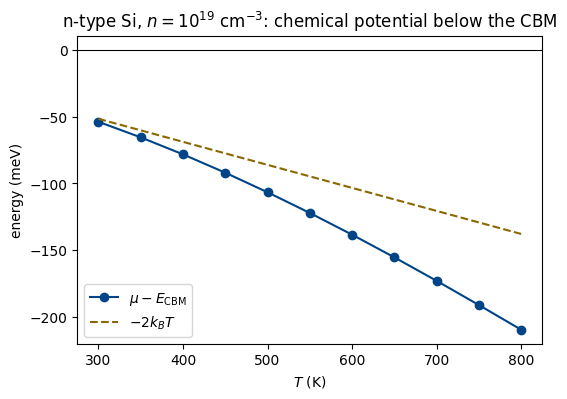

In [8]:
import matplotlib.pyplot as plt
import numpy as np

temperature, mu = np.loadtxt('output/doping_n1e+19.dat', unpack=True)
E_CBM = 0.754  # eV above the VBM
kB = 8.617333e-5  # eV/K

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(temperature, 1000 * (mu - E_CBM), 'o-', color='#004488', label=r'$\mu - E_\mathrm{CBM}$')
ax.plot(temperature, -2000 * kB * temperature, '--', color='#8A6800', label=r'$-2k_BT$')
ax.axhline(0.0, color='#000000', lw=0.8)
ax.set_xlabel('$T$ (K)')
ax.set_ylabel('energy (meV)')
ax.set_title(r'n-type Si, $n = 10^{19}$ cm$^{-3}$: chemical potential below the CBM')
ax.legend()
plt.show()

At 300 K, $\mu$ lies 54 meV, about $2k_BT$, below the CBM, so the electrons are close to degenerate. As the temperature rises, they spread over more states above the CBM, and $\mu$ moves down, to 210 meV below the CBM at 800 K. This is faster than $2k_BT$: at 800 K, $\mu$ lies $3.0\,k_BT$ below the CBM, so the electron gas becomes less degenerate as it warms. These values carry the mesh error of the first step, 14 meV at 300 K.

## Energy-dependent relaxation times

In this step you replace the constant $\tau$ by relaxation times that depend on the energy of the carrier and on temperature, and compute the resistivity of the n-type Si of the previous step. A constant $\tau$ is a poor approximation in a semiconductor. Its carriers spread over several $k_BT$ above the band edge, and the scattering rate changes across them.

`transport()` therefore takes a list of scattering channels and adds their rates state by state, $1/\tau_{n\mathbf{k}} = \sum_c w_c/\tau_c(\varepsilon_{n\mathbf{k}}, T)$. This is Matthiessen's rule ([Matthiessen's rule](../theory/boltzmann-transport.md#matthiessens-rule)). The weights $w_c$ are set by `scattering_weights`, 1 by default. A channel takes one of two forms:

| Channel | Given as | Parameters |
| --- | --- | --- |
| Built-in model | its name: `'acoustic'`, `'optical'`, `'impurity'`, `'polar_optical'` or `'polar_acoustic'` | read from the dictionary `tau_dict`; the docstring of each model in {py:mod}`PAOFLOW.boltzmann.do_tau_models` lists the keys it reads, with their units |
| Your own model | a `TauModel` object that holds your function | the `params` of the `TauModel` |

Each model receives $k_BT$ in eV and the band energies $|\varepsilon_{n\mathbf{k}}|$ in eV, and returns $\tau$ in seconds.

The built-in models are textbook rates for one isotropic parabolic band of effective mass $m^*$ (`ms`). They therefore miss the anisotropic masses of the Si valleys and intervalley scattering ([Built-in scattering models](../theory/boltzmann-transport.md#built-in-scattering-models)). This tutorial uses acoustic-phonon scattering through the deformation potential, whose rate for an electron of kinetic energy $E$ is

$$
\frac{1}{\tau_\mathrm{ac}(E, T)} = \frac{(2m^*)^{3/2} D_\mathrm{ac}^2\, k_BT \sqrt{E}}{2\pi \rho\, \hbar^4 v_s^2} ,
$$

with $D_\mathrm{ac}$, $\rho$ and $v_s$ set by keys of `tau_parameters` (see the table below). To this you add scattering by the ionised donors (`'impurity'`), with $n_I = 10^{19}$ cm$^{-3}$ singly charged impurities, the doping of the previous step. The built-in impurity model screens the Coulomb potential with $\varepsilon_s + \varepsilon_\infty$. For Si, where both are 11.7, this sum is twice the static dielectric constant. The keys of `tau_parameters` in the cell below set the parameters of both models:

| Key | Symbol | Meaning | Model |
| --- | --- | --- | --- |
| `ms` | $m^*$ | effective mass, in units of $m_e$ | both |
| `D_ac` | $D_\mathrm{ac}$ | deformation potential | acoustic |
| `rho` | $\rho$ | mass density | acoustic |
| `v` | $v_s$ | sound velocity | acoustic |
| `nI`, `Zi` | $n_I$, $Z_i$ | density and charge of the impurities | impurity |
| `eps_0`, `eps_inf` | $\varepsilon_s$, $\varepsilon_\infty$ | static and high-frequency dielectric constants | impurity |

The parameters are illustrative and not fitted to experiment.

The rate above assumes the kinetic energy of the electron. The built-in models, however, take $E = |\varepsilon_{n\mathbf{k}}|$, measured from the energy zero of the run, the VBM. For an electron in the conduction band, this $E$ is 0.754 eV plus its kinetic energy ([Energy reference of the built-in models](../theory/boltzmann-transport.md#energy-reference-of-the-built-in-models)). To use the kinetic energy instead, you write the acoustic model as a `TauModel` that measures the conduction states from the CBM. The cell prints $\tau_\mathrm{ac}$ at 300 K for an electron $k_BT$ above the CBM, with the energy measured both ways.

In [9]:
from scipy.constants import e, hbar, m_e

from PAOFLOW.boltzmann.TauModel import TauModel


def acoustic_tau(temp, eigs, params):
    """Acoustic deformation-potential relaxation time (s), energies from the band edges."""
    # eigs is |eps_nk| from the VBM: conduction states are measured from the CBM E_c,
    # valence states (holes) stay measured from the VBM
    energy = np.where(eigs >= params['E_c'], eigs - params['E_c'], eigs) * e
    kT = temp * e
    mass = params['ms'] * m_e
    deformation = params['D_ac'] * e
    tau = np.full_like(energy, np.inf)
    moving = energy > 0.0
    numerator = 2 * np.pi * params['rho'] * (hbar**2 * params['v']) ** 2
    tau[moving] = numerator / ((2 * mass) ** 1.5 * deformation**2 * np.sqrt(energy[moving]) * kT)
    return tau


tau_parameters = {
    'v': 9.0e3,  # sound velocity (m/s)
    'rho': 2.33e3,  # mass density (kg/m^3)
    'ms': 0.26,  # effective mass (m_e)
    'D_ac': 5.0,  # deformation potential (eV)
    'nI': 1.0e19,  # ionised impurities (cm^-3)
    'Zi': 1,  # impurity charge
    'eps_0': 11.7,
    'eps_inf': 11.7,
}
E_CBM = 0.754  # CBM of this run (eV above the VBM)
custom_acoustic = TauModel(function=acoustic_tau, params={**tau_parameters, 'E_c': E_CBM})

kT_300 = 300.0 * 8.617333e-5
electron = np.array([E_CBM + kT_300])
tau_cbm = acoustic_tau(kT_300, electron, {**tau_parameters, 'E_c': E_CBM})[0]
tau_vbm = acoustic_tau(kT_300, electron, {**tau_parameters, 'E_c': 0.0})[0]
print(f'tau_ac, energy from the CBM: {tau_cbm:.2e} s')
print(f'tau_ac, energy from the VBM: {tau_vbm:.2e} s')

# tau_ac at 300 K of conduction electrons up to 0.3 eV above the CBM, with the energy measured both ways
above_cbm = np.linspace(0.001, 0.3, 300)
np.savetxt(
    'output/tau_acoustic.dat',
    np.column_stack(
        [
            above_cbm,
            acoustic_tau(kT_300, E_CBM + above_cbm, {**tau_parameters, 'E_c': E_CBM}),
            acoustic_tau(kT_300, E_CBM + above_cbm, {**tau_parameters, 'E_c': 0.0}),
        ]
    ),
    header='E - E_CBM (eV), tau_ac from the CBM (s), tau_ac from the VBM (s)',
)

tau_ac, energy from the CBM: 2.63e-12 s
tau_ac, energy from the VBM: 4.79e-13 s


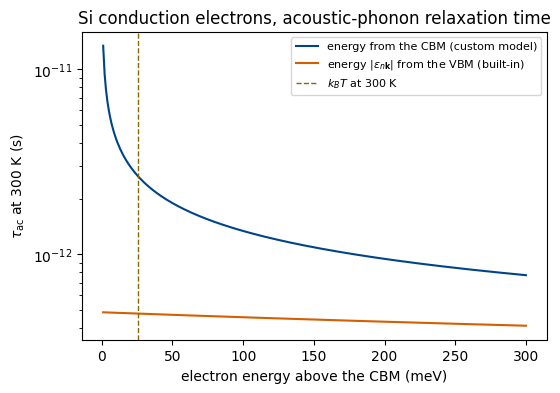

In [10]:
import matplotlib.pyplot as plt
import numpy as np

above_cbm, tau_cbm, tau_vbm = np.loadtxt('output/tau_acoustic.dat', unpack=True)
kT_300 = 300.0 * 8.617333e-5

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(1000 * above_cbm, tau_cbm, color='#004488', label='energy from the CBM (custom model)')
ax.semilogy(
    1000 * above_cbm,
    tau_vbm,
    color='#D55E00',
    label=r'energy $|\varepsilon_{n\mathbf{k}}|$ from the VBM (built-in)',
)
ax.axvline(1000 * kT_300, color='#8A6800', ls='--', lw=1.0, label=r'$k_BT$ at 300 K')
ax.set_xlabel(r'electron energy above the CBM (meV)')
ax.set_ylabel(r'$\tau_\mathrm{ac}$ at 300 K (s)')
ax.set_title('Si conduction electrons, acoustic-phonon relaxation time')
ax.legend(fontsize=8)
plt.show()

For this electron, $\tau_\mathrm{ac}$ is $2.63\times10^{-12}$ s with the kinetic energy and $4.79\times10^{-13}$ s with the energy measured from the VBM. The built-in convention therefore makes acoustic scattering of conduction electrons 5.5 times faster, the factor $\sqrt{0.780/0.026}$.

The figure shows that the two conventions also differ in how $\tau_\mathrm{ac}$ depends on energy. Measured from the CBM, $\tau_\mathrm{ac} \propto E^{-1/2}$ grows towards the band edge, so the slowest electrons scatter least. Measured from the VBM, the energy changes only from 0.754 to 1.054 eV over the range shown, so $\tau_\mathrm{ac}$ varies by 18% and the energy dependence of the scattering is lost. The two relaxation times still differ by a factor of 1.9 at 0.3 eV.

The custom model keeps the valence states measured from the VBM, which for holes is their kinetic energy. The model is therefore correct for all conduction states and for the valence states within 0.754 eV of the VBM. In n-type Si these are the only valence states that carry current.

### Resistivity of n-type Si

Now run `transport()` once per temperature, at the $\mu(T)$ of the previous step, for two sets of channels:

- the built-in acoustic and impurity models;
- the custom acoustic model with the built-in impurity model.

Each call evaluates a single $(T, \mu)$ point and rewrites `sigmagauss_0.dat`, so the cell reads the conductivity right after the call. The resistivity is the inverse of the trace average of the diagonal components, $\rho = 3/(\sigma_{xx}+\sigma_{yy}+\sigma_{zz})$, converted from $\Omega$ m to $\Omega$ cm.

The calls also overwrite the constant-$\tau$ files of [Transport tensors in the constant relaxation-time approximation](#transport-tensors-in-the-constant-relaxation-time-approximation). To redraw that figure, run its `transport()` call again.

**Output:** `resistivity.dat`, with the columns $T$ (K), $\rho$ with the built-in channels and $\rho$ with the custom acoustic model ($\Omega$ cm).

In [11]:
channel_sets = {
    'built-in acoustic + impurity': ['acoustic', 'impurity'],
    'custom acoustic + built-in impurity': [custom_acoustic, 'impurity'],
}
resistivity = {}
for label, channels in channel_sets.items():
    rho = []
    for t, m in zip(temperature, mu):
        paoflow.transport(
            tmin=t,
            tmax=t,
            emin=m,
            emax=m,
            ne=1,
            scattering_channels=channels,
            tau_dict=tau_parameters,
        )
        row = np.loadtxt('output/sigmagauss_0.dat')
        rho.append(100.0 * 3.0 / row[2:5].sum())
    resistivity[label] = np.array(rho)

np.savetxt(
    'output/resistivity.dat',
    np.column_stack([temperature, *resistivity.values()]),
    header='T (K), rho built-in (Ohm cm), rho custom acoustic (Ohm cm)',
)
paoflow.finish_execution()

Transport in:                               1.913 sec


Transport in:                               1.675 sec


Transport in:                               1.634 sec


Transport in:                               1.683 sec


Transport in:                               1.627 sec


Transport in:                               1.632 sec


... (13 outputs left out)

Transport in:                               2.095 sec


Transport in:                               2.068 sec


Transport in:                               2.071 sec


Total CPU time =                          117.766 sec


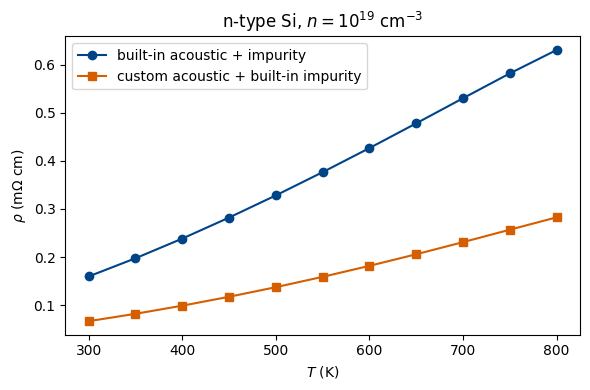

In [12]:
import matplotlib.pyplot as plt
import numpy as np

temperature, rho_builtin, rho_custom = np.loadtxt('output/resistivity.dat', unpack=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(temperature, 1e3 * rho_builtin, 'o-', color='#004488', label='built-in acoustic + impurity')
ax.plot(
    temperature,
    1e3 * rho_custom,
    's-',
    color='#D55E00',
    label='custom acoustic + built-in impurity',
)
ax.set_xlabel('$T$ (K)')
ax.set_ylabel(r'$\rho$ (m$\Omega$ cm)')
ax.set_title(r'n-type Si, $n = 10^{19}$ cm$^{-3}$')
ax.legend()
fig.tight_layout()
plt.show()

Both resistivities rise with temperature as acoustic-phonon scattering grows. The two sets of channels differ only in the energy reference of the acoustic model:

| Channels | $\rho$ at 300 K (m$\Omega$ cm) | $\rho$ from 300 to 800 K | Mobility $1/(e n \rho)$ at 300 K (cm$^2$/(V s)) |
| --- | --- | --- | --- |
| built-in acoustic + impurity | 0.160 | rises by a factor of 3.9 | 3900 |
| custom acoustic + built-in impurity | 0.067 | rises by a factor of 4.2 | 9300 |

At 300 K the custom model gives a resistivity 2.4 times lower, because the built-in model makes the acoustic rate of conduction electrons too fast by the factor found above.

The built-in impurity model also evaluates its rate at $|\varepsilon_{n\mathbf{k}}|$. Its rate falls as $E^{-3/2}$, so at 0.75 eV above the VBM it is much weaker than at the kinetic energy of the electrons. A `TauModel` written in the same way corrects it.

The parameters are illustrative and the model has no intervalley scattering. These numbers therefore show how the result depends on the choice of channels and of the energy reference, not the mobility of real Si.

## Where to go next

- [Boltzmann transport in the relaxation-time approximation](../theory/boltzmann-transport.md) derives the moments, the chemical potential at fixed doping and the scattering models, and says where each approximation fails.
- [Scattering channels](../../internals/scattering-channels.md) describes the channels built from first-principles electron–phonon calculations, which replace the model relaxation times used here.
- {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.transport` and {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.doping` list all arguments, including the [Hall coefficient](../theory/boltzmann-transport.md#hall-coefficient) (`do_hall=True`, after `gradient_and_momenta(band_curvature=True)`).
- [Relaxation time approximations in PAOFLOW 2.0](https://doi.org/10.1038/s41598-022-08931-5) applies the built-in scattering models to other materials.